<a href="https://colab.research.google.com/github/barthwalarchi956-ui/GEE-code/blob/main/s2_turbidity_pipeline_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sentinel-2 Harmonized (Copernicus) Turbidity Pipeline

Downloads **Sentinel-2 L2A (Copernicus, harmonized)** for the Ganga buffer, builds a clear-water median composite for each period, runs your trained model and writes **`turbidity_ntu` GeoTIFFs**. **No Google Earth Engine.**

| Item | Choice |
|---|---|
| Data source | Earth Search STAC (`sentinel-2-l2a`, Copernicus COGs on AWS, free, no key) |
| Harmonization | processing-baseline ≥ 04.00 offset (−1000 DN) removed → same as `S2_SR_HARMONIZED` |
| Model features (as in your figure) | `blue, green, red, nir` + `NDTI = (red − green)/(red + green)` (NDTI is computed inside the model pipeline) |
| Bands | blue = B02, green = B03, red = B04, **nir = B8A** (the `nir` column of your training CSV; `nir_broad` is B08) |
| Mask | cloud/shadow/snow removed with SCL, water = SCL water **or** NDWI > 0 |
| Periods | 1–15 Oct 2026 and 16–31 Oct 2026 |
| Output | **exactly two files**: `turbidity_ntu_20261001_20261015.tif` and `turbidity_ntu_20261016_20261031.tif` (float32, NTU, nodata = −9999, UTM 44N) |

In [ ]:
!pip install -q pystac-client geopandas rasterio pandas scikit-learn joblib matplotlib shapely

## 1. Settings

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ---- paths (edit) -------------------------------------------------------------------------
SHP_PATH   = "/content/drive/MyDrive/wq_products_generator-main/Ganga_Buffer_2km/Ganga_Buffer_2km.shp"           # keep .shx/.dbf/.prj next to it if you have them
MODEL_PATH = "/content/drive/MyDrive/turbidity_mgl/turbidity_model_final_all_labeled.pkl"
LIB_DIR    = "turbidity_pipeline"             # folder with turbidity_lib.py (required to unpickle the model)
OUT_DIR    = "s2_turbidity_out"

# ---- periods ------------------------------------------------------------------------------
PERIODS = [("2026-10-01", "2026-10-15"),
           ("2026-10-16", "2026-10-31")]

# ---- processing options -------------------------------------------------------------------
RES         = 30.0     # output pixel size (m). 30 m matches the HLS data the model was trained on
MAX_CLOUD   = 70.0     # scene-level eo:cloud_cover filter (%); pixel-level masking is done with SCL
WATER_MASK  = "scl_or_ndwi"   # "scl" | "scl_or_ndwi" | "none" (predict on every clear pixel)
BLOCK       = 1024     # processing tile (pixels); lower it if you run out of RAM
MAX_BLOCKS  = None     # e.g. 3 for a quick test run, None = whole area

# shapefile has no .prj in the upload; its coordinates are degrees, so EPSG:4326 is assumed
SHP_CRS_IF_MISSING = "EPSG:4326"

## 2. Functions

In [ ]:
import os, sys, warnings
os.environ["SHAPE_RESTORE_SHX"] = "YES"        # lets GDAL rebuild a missing .shx
import numpy as np, pandas as pd, geopandas as gpd, rasterio, joblib
from contextlib import ExitStack
from rasterio.features import geometry_mask
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling
from rasterio.windows import Window, transform as win_transform
from rasterio.transform import from_origin
from shapely.geometry import shape as shp_shape
from pystac_client import Client
warnings.filterwarnings("ignore")

STAC_URL, COLLECTION = "https://earth-search.aws.element84.com/v1", "sentinel-2-l2a"
BANDS   = {"blue": "blue", "green": "green", "red": "red", "nir": "nir08"}   # nir08 = B8A
FEATURES = ["blue", "green", "red", "nir"]        # model input; NDTI is built inside the model
NODATA  = -9999.0
GDAL_ENV = dict(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", CPL_VSIL_CURL_ALLOWED_EXTENSIONS=".tif,.TIF",
                GDAL_HTTP_MULTIPLEX="YES", GDAL_HTTP_MAX_RETRY="4", GDAL_HTTP_RETRY_DELAY="2",
                VSI_CACHE="TRUE", GDAL_CACHEMAX=512)

def to_refl(dn, item):
    """DN -> surface reflectance (0-1), harmonized across the 2022-01 processing-baseline change."""
    pb = float(str(item.properties.get("s2:processing_baseline", "0") or "0"))
    already = bool(item.properties.get("earthsearch:boa_offset_applied", False))
    off = -0.1 if (pb >= 4.0 and not already) else 0.0
    return np.clip(dn.astype("float32") * 1e-4 + off, 0, None)

def make_grid(aoi_ll, res):
    c = aoi_ll.centroid
    crs = f"EPSG:{(32600 if c.y >= 0 else 32700) + int((c.x + 180) // 6) + 1}"
    minx, miny, maxx, maxy = gpd.GeoSeries([aoi_ll], crs="EPSG:4326").to_crs(crs).total_bounds
    minx, maxy = np.floor(minx / res) * res, np.ceil(maxy / res) * res
    shape = (int(np.ceil((maxy - miny) / res)), int(np.ceil((maxx - minx) / res)))
    return crs, from_origin(minx, maxy, res, res), shape

def item_bounds(item):
    return gpd.GeoSeries([shp_shape(item.geometry)], crs="EPSG:4326").to_crs(GRID_CRS).total_bounds

def process_period(items, start, end):
    """Block-wise: read clear water pixels of every scene -> median composite -> model -> GeoTIFF."""
    H, W = GRID_SHAPE
    tag = f"{start.replace('-', '')}_{end.replace('-', '')}"
    out_t = f"{OUT_DIR}/turbidity_ntu_{tag}.tif"
    prof = dict(driver="GTiff", height=H, width=W, crs=GRID_CRS, transform=GRID_TRANSFORM, dtype="float32",
                nodata=NODATA, compress="deflate", predictor=3, tiled=True, blockxsize=256, blockysize=256,
                BIGTIFF="IF_SAFER")
    ib = [(it, item_bounds(it)) for it in items]
    down = RES >= 20
    rs_band = Resampling.average if down else Resampling.bilinear
    blocks = [(r, c) for r in range(0, H, BLOCK) for c in range(0, W, BLOCK)]
    done, npx, sample, used_ids = 0, 0, [], set()

    with ExitStack() as stack, rasterio.Env(**GDAL_ENV):
        dst_t = stack.enter_context(rasterio.open(out_t, "w", count=1, **prof))
        dst_t.set_band_description(1, "turbidity_ntu")
        cache = {}
        def vrt(it, key, rs):
            k = (it.id, key)
            if k not in cache:
                src = stack.enter_context(rasterio.open(it.assets[key].href))
                cache[k] = stack.enter_context(WarpedVRT(src, crs=GRID_CRS, transform=GRID_TRANSFORM,
                                width=W, height=H, resampling=rs, src_nodata=0, nodata=0))
            return cache[k]

        for bi, (r0, c0) in enumerate(blocks, 1):
            h, w = min(BLOCK, H - r0), min(BLOCK, W - c0)
            win = Window(c0, r0, w, h)
            bt = win_transform(win, GRID_TRANSFORM)
            aoi_b = geometry_mask(AOI_UTM, out_shape=(h, w), transform=bt, invert=True)
            if not aoi_b.any(): continue
            if MAX_BLOCKS is not None and done >= MAX_BLOCKS: break
            x0, y1 = bt.c, bt.f; x1, y0 = x0 + w * RES, y1 - h * RES
            stacks = {k: [] for k in FEATURES}
            for it, (a, b, c_, d) in ib:
                if c_ < x0 or a > x1 or d < y0 or b > y1: continue       # scene does not touch this block
                try:
                    scl = vrt(it, "scl", Resampling.nearest).read(1, window=win)
                    clear = np.isin(scl, [4, 5, 6, 7]) & aoi_b            # veg, bare, water, unclassified
                    if not clear.any(): continue
                    dn = {n: vrt(it, k, rs_band).read(1, window=win) for n, k in BANDS.items()}
                    refl = {n: to_refl(v, it) for n, v in dn.items()}
                    ok = clear & np.all([dn[n] > 0 for n in FEATURES], axis=0)
                    if WATER_MASK == "scl":
                        ok &= (scl == 6)
                    elif WATER_MASK == "scl_or_ndwi":
                        ndwi = (refl["green"] - refl["nir"]) / (refl["green"] + refl["nir"] + 1e-6)
                        ok &= (scl == 6) | (ndwi > 0)
                    if not ok.any(): continue
                    for n in FEATURES:
                        a_ = refl[n]; a_[~ok] = np.nan; stacks[n].append(a_)
                    used_ids.add(it.id)
                except Exception as e:
                    print(f"    ! {it.id} block {bi}: {type(e).__name__}: {e}")
            done += 1
            if not stacks["blue"]:
                print(f"  block {bi}/{len(blocks)}: no clear water"); continue
            comp = {n: np.nanmedian(np.stack(v), axis=0) for n, v in stacks.items()}
            valid = np.all([~np.isnan(comp[n]) for n in FEATURES], axis=0)
            turb = np.full((h, w), NODATA, dtype="float32")
            if valid.any():
                X = pd.DataFrame({n: comp[n][valid] for n in FEATURES})
                turb[valid] = np.clip(MODEL.predict(X), 0, None).astype("float32")
                npx += int(valid.sum()); sample.append(turb[valid][::37])
            dst_t.write(turb, 1, window=win)
            print(f"  block {bi}/{len(blocks)}: {int(valid.sum())} water px, {len(stacks['blue'])} scene-layers")
        dst_t.update_tags(period=f"{start}/{end}", scenes_used=str(len(used_ids)), units="NTU",
                          source="Sentinel-2 L2A harmonized (Copernicus) via Earth Search", features="blue,green,red,nir,NDTI")
    s = np.concatenate(sample) if sample else np.array([])
    print(f"  -> {out_t} | water px: {npx} | scenes used: {len(used_ids)}" +
          (f" | NTU p5/median/p95: {np.percentile(s,5):.0f}/{np.median(s):.0f}/{np.percentile(s,95):.0f}" if s.size else ""))
    return out_t if npx else None

In [ ]:
!pip install pystac-client

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25/25 [pystac-client]


## 3. Load model and area (shapefile)

In [ ]:
import os

# Quick diagnostic helper
if not os.path.exists("/content/drive/MyDrive"):
    print("WARNING: Google Drive is not mounted yet. Please run cell QvZhsvf1AM-M and follow the authorization prompt.")
else:
    parent_dir = "/content/drive/MyDrive/turbidity_mgl"
    if os.path.exists(parent_dir):
        print(f"Files inside '{parent_dir}':", os.listdir(parent_dir))
    else:
        print(f"WARNING: The folder '{parent_dir}' does not exist in your Google Drive. Please verify the folder name in Drive.")

# Construct the absolute path to turbidity_pipeline in Google Drive
full_lib_path = os.path.join("/content/drive/MyDrive/turbidity_mgl", LIB_DIR)
sys.path.insert(0, os.path.abspath(full_lib_path))

os.makedirs(OUT_DIR, exist_ok=True)
MODEL = joblib.load(MODEL_PATH)
print("model:", type(MODEL).__name__, "| inputs:", FEATURES, "(+ NDTI inside the pipeline)")

gdf = gpd.read_file(SHP_PATH)
if gdf.crs is None:
    print(f"shapefile has no CRS -> assuming {SHP_CRS_IF_MISSING}")
    gdf = gdf.set_crs(SHP_CRS_IF_MISSING)
gdf = gdf.to_crs("EPSG:4326")
AOI = gdf.geometry.union_all() if hasattr(gdf.geometry, "union_all") else gdf.geometry.unary_union
GRID_CRS, GRID_TRANSFORM, GRID_SHAPE = make_grid(AOI, RES)
AOI_UTM = list(gpd.GeoSeries([AOI], crs="EPSG:4326").to_crs(GRID_CRS))
print(f"AOI bounds (lon/lat): {np.round(AOI.bounds, 3)}")
print(f"output grid: {GRID_CRS}, {GRID_SHAPE[1]} x {GRID_SHAPE[0]} px @ {RES:g} m")

Files inside '/content/drive/MyDrive/turbidity_mgl': ['model_comparison.png', 'model_r2_report.txt', 'turbidity_vs_5_features.png', 'turbidity_pipeline.py', 'test_predictions.csv', 'turbidity_model_final_all_labeled.pkl', 'turbidity_pipeline.zip', 'turbidity_pipeline', 'New folder', '.vscode']
model: AugRegressor | inputs: ['blue', 'green', 'red', 'nir'] (+ NDTI inside the pipeline)
AOI bounds (lon/lat): [80.282 25.097 83.068 26.58 ]
output grid: EPSG:32644, 9322 x 5440 px @ 30 m


## 4. Search, download, composite, predict → GeoTIFF

This streams only the needed windows of the Sentinel-2 COGs. A full-area run over two half-month periods can take a while; set `MAX_BLOCKS = 3` in the settings first for a quick test.

In [ ]:
catalog = Client.open(STAC_URL)
results = {}
for start, end in PERIODS:
    print(f"\n=== {start} -> {end} ===")
    search = catalog.search(collections=[COLLECTION], bbox=list(AOI.bounds),
                            datetime=f"{start}T00:00:00Z/{end}T23:59:59Z",
                            query={"eo:cloud_cover": {"lt": MAX_CLOUD}})
    items = [i for i in search.items() if shp_shape(i.geometry).intersects(AOI)]
    items.sort(key=lambda i: i.datetime)
    print(f"  {len(items)} scenes (tiles x dates) touch the area")
    for i in items:
        print(f"    {i.datetime:%Y-%m-%d}  {i.id}  cloud={i.properties.get('eo:cloud_cover', float('nan')):.0f}%  "
              f"baseline={i.properties.get('s2:processing_baseline')}  offset_applied={i.properties.get('earthsearch:boa_offset_applied')}")
    results[(start, end)] = process_period(items, start, end) if items else None
print("\nDone:", results)


=== 2026-10-01 -> 2026-10-15 ===
  36 scenes (tiles x dates) touch the area
    2026-10-01  S2C_44RQP_20261001_0_L2A  cloud=13%  baseline=05.13  offset_applied=True
    2026-10-01  S2C_44RPP_20261001_0_L2A  cloud=9%  baseline=05.13  offset_applied=True
    2026-10-01  S2C_44RQN_20261001_0_L2A  cloud=16%  baseline=05.13  offset_applied=True
    2026-10-01  S2C_44RPN_20261001_0_L2A  cloud=18%  baseline=05.13  offset_applied=True
    2026-10-02  S2B_44RMQ_20261002_0_L2A  cloud=0%  baseline=05.13  offset_applied=True
    2026-10-03  S2A_44RQP_20261003_0_L2A  cloud=2%  baseline=05.13  offset_applied=True
    2026-10-03  S2A_44RPP_20261003_0_L2A  cloud=0%  baseline=05.13  offset_applied=True
    2026-10-03  S2A_44RQN_20261003_0_L2A  cloud=6%  baseline=05.13  offset_applied=True
    2026-10-03  S2A_44RPN_20261003_0_L2A  cloud=0%  baseline=05.13  offset_applied=True
    2026-10-04  S2C_44RMQ_20261004_0_L2A  cloud=0%  baseline=05.13  offset_applied=True
    2026-10-04  S2C_44RPP_20261004_0_L2A

In [2]:

# ============================================================
# COPY GENERATED TURBIDITY TIFF FILES TO GOOGLE DRIVE
# Does NOT require the results variable
# ============================================================

from google.colab import drive
import os
import shutil
import rasterio

# Mount Google Drive if not already mounted
if not os.path.isdir("/content/drive/MyDrive"):
    drive.mount("/content/drive")

# Source folder defined in your notebook (OUT_DIR)
SOURCE_DIR = OUT_DIR if "OUT_DIR" in globals() else "s2_turbidity_out"

# Google Drive destination
DRIVE_DIR = "/content/drive/MyDrive/Turbidity_TIFF_October_2026"
os.makedirs(DRIVE_DIR, exist_ok=True)

# Expected output TIFFs from your process_period() function
expected_files = [
    "turbidity_ntu_20261001_20261015.tif",
    "turbidity_ntu_20261016_20261031.tif"
]

print("Source:", os.path.abspath(SOURCE_DIR))
print("Destination:", DRIVE_DIR)

copied = 0

for filename in expected_files:

    src = os.path.join(SOURCE_DIR, filename)

    if not os.path.isfile(src):
        print(f"NOT FOUND: {src}")
        continue

    dst = os.path.join(DRIVE_DIR, filename)

    shutil.copy2(src, dst)

    # Verify TIFF
    with rasterio.open(dst) as tif:
        print(f"\nSUCCESS: {filename}")
        print("CRS:", tif.crs)
        print("Resolution:", tif.res)
        print("Dimensions:", tif.width, "x", tif.height)
        print("Units:", tif.tags().get("units", "NTU"))
        print("File size: %.2f MB" %
              (os.path.getsize(dst) / (1024 * 1024)))

    copied += 1

print("\n================================")
print("TIFF EXPORT COMPLETED")
print("Files copied:", copied, "/ 2")
print("Google Drive:", DRIVE_DIR)
print("================================")



Source: /content/s2_turbidity_out
Destination: /content/drive/MyDrive/Turbidity_TIFF_October_2026
NOT FOUND: s2_turbidity_out/turbidity_ntu_20261001_20261015.tif
NOT FOUND: s2_turbidity_out/turbidity_ntu_20261016_20261031.tif

TIFF EXPORT COMPLETED
Files copied: 0 / 2
Google Drive: /content/drive/MyDrive/Turbidity_TIFF_October_2026


## 5. Preview

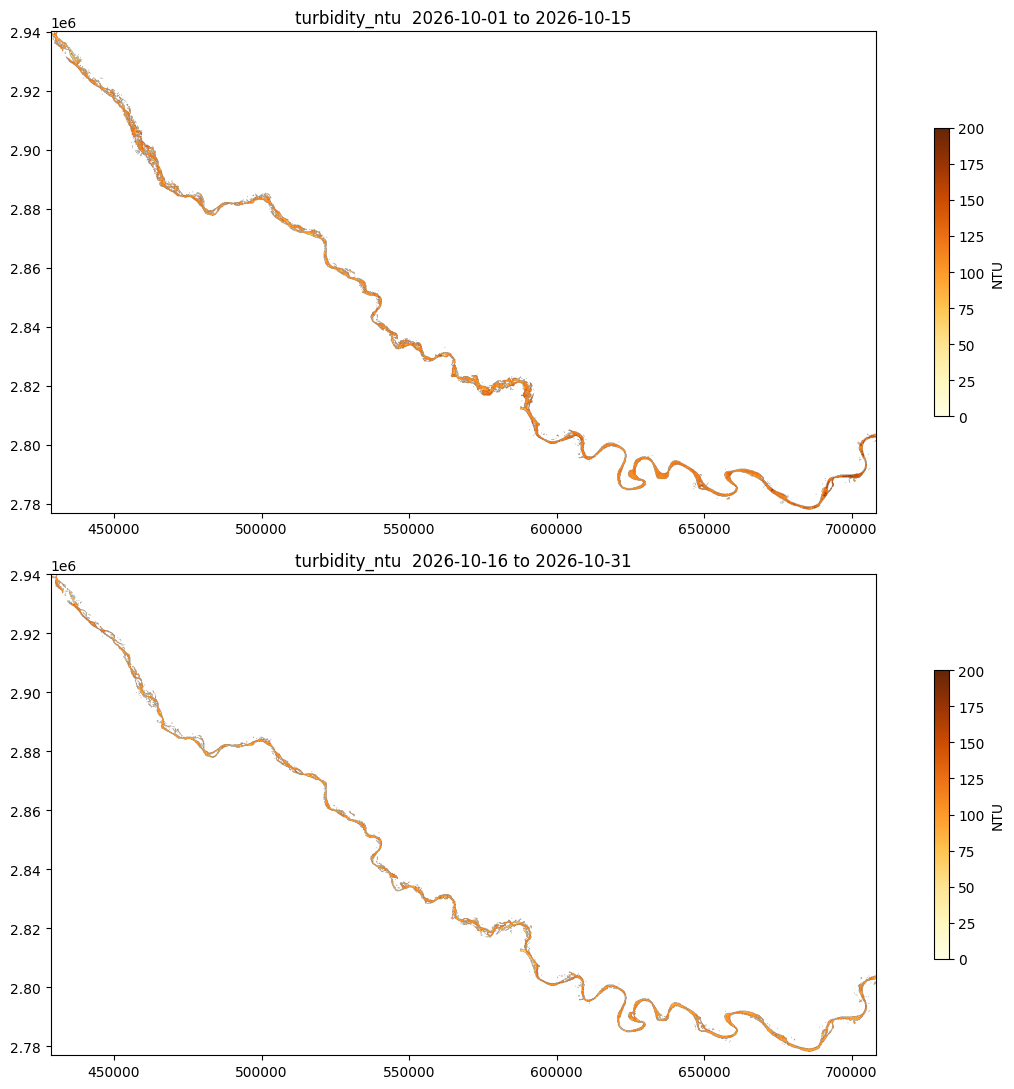

In [ ]:
import matplotlib.pyplot as plt
files = [(k, v) for k, v in results.items() if v]
fig, axs = plt.subplots(len(files), 1, figsize=(12, 5.5 * max(1, len(files))), squeeze=False)
for ax, ((s, e), path) in zip(axs[:, 0], files):
    with rasterio.open(path) as src:
        step = max(1, max(src.height, src.width) // 1500)
        a = src.read(1, out_shape=(src.height // step, src.width // step), resampling=Resampling.nearest)
        ext = (src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top)
    im = ax.imshow(np.ma.masked_equal(a, NODATA), cmap="YlOrBr", vmin=0, vmax=200, extent=ext)
    ax.set_title(f"turbidity_ntu  {s} to {e}"); plt.colorbar(im, ax=ax, shrink=0.6, label="NTU")
plt.tight_layout(); plt.show()

In [4]:
cmap="YlOrBr"
vmin=0
vmax=200